# 06 Objectives

Same LightGBM features, parameters and origins as the baseline. Only the training objective changes. Runs in under a minute.


In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import time

import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, series_segments, H, FREQ, ALL_CUTOFFS, DEV_CUTOFFS, TEST_CUTOFF
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS
from shared.evaluation import score
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard, breakdown

panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]
segments = series_segments(panel)

## 1. Why the objective matters

The objective decides which number the trees aim for.

- **L2** (squared error, LightGBM's default) aims for the conditional mean. Squaring makes a 10-unit miss count 100 times as much as a 1-unit miss, so a few large promotion spikes pull the fit, and the forecast for ordinary weeks, upward.
- **L1** (absolute error) aims for the conditional median. A spike counts in proportion to its size, so it moves the fit much less. For skewed sales the median sits below the mean, and for products that sell nothing most weeks it can be zero.
- **Tweedie** fits non-negative, skewed data with exact zeros, on a log link, so effects are multiplicative. `tweedie_variance_power` sets how the variance grows with the mean: 1 is Poisson, 2 is gamma, and values in between allow a mass of zeros plus a continuous tail. We use 1.3.
- **Quantile** at 0.6 aims slightly above the median, as a check on whether deliberately higher forecasts help.

### What each objective estimates, and what WAPE rewards

- The single value with the smallest total absolute error is the median; the value with the smallest squared error is the mean. So L1 estimates the conditional median, and L2 the conditional mean. Tweedie also estimates a mean, through a log link.
- WAPE is total absolute error over total sales. It rewards the median, so L1 trains on the same kind of loss that WAPE measures.
- Weekly sales are right-skewed, so the median sits below the mean. A median forecast is low on average, and summed over products and weeks that appears as negative bias. A mean forecast has no such bias in principle.

The results below show the trade: L1 has the lowest WAPE and a negative bias. Of the mean-targeting models, raw Tweedie comes close to zero bias (+0.008 on development), while L2 overforecasts (+0.139), as the spike example in section 5 illustrates.

## 2. Configuration

Every model uses the 02 lags, rolling means and calendar features and these LightGBM parameters:

In [3]:
LGB_PARAMS

{'n_estimators': 300,
 'learning_rate': 0.05,
 'num_leaves': 31,
 'min_child_samples': 50,
 'subsample': 0.8,
 'subsample_freq': 1,
 'colsample_bytree': 0.8,
 'random_state': 0,
 'verbosity': -1}

Tweedie needs a non-negative target, and the standardized target is centered at zero, so the comparison has two controlled blocks:

| target | L2 (notebook 02) | L1 | other |
|---|---|---|---|
| standardized per series | `lgbm_baseline` | `lgbm_l1_std` | `lgbm_quantile60_std` |
| raw units | `lgbm_raw` | `lgbm_l1_raw` | `lgbm_tweedie_raw` |

Within a block, only the objective differs. The L2 models are loaded from notebook 02, where they were fit with these same settings at the same origins. L1 and Tweedie can be compared only on the raw target.

In [4]:
def make_model(name, objective_params, target_transforms):
    return MLForecast(
        models={name: lgb.LGBMRegressor(**dict(LGB_PARAMS, **objective_params))},
        freq=FREQ,
        lags=LAGS,
        lag_transforms=LAG_TRANSFORMS,
        date_features=DATE_FEATURES,
        target_transforms=target_transforms,
        num_threads=1,
    )

models = [
    make_model("lgbm_l1_std", {"objective": "l1"}, [LocalStandardScaler()]),
    make_model("lgbm_quantile60_std", {"objective": "quantile", "alpha": 0.6}, [LocalStandardScaler()]),
    make_model("lgbm_l1_raw", {"objective": "l1"}, []),
    make_model("lgbm_tweedie_raw", {"objective": "tweedie", "tweedie_variance_power": 1.3}, []),
]

## 3. Fit at every origin

Fit time is fit plus 14-week forecast, summed over the ten origins.

In [5]:
forecasts, fit_seconds = [], {}
for cutoff in ALL_CUTOFFS:
    train = actuals[actuals.ds <= cutoff]
    for mlf in models:
        start = time.perf_counter()
        mlf.fit(train)
        preds = mlf.predict(H)
        name = preds.columns[-1]
        fit_seconds[name] = fit_seconds.get(name, 0) + time.perf_counter() - start
        forecasts.append(to_long(preds, cutoff, "06_objectives"))

forecasts = pd.concat(forecasts)

## 4. Results

All six models on identical rows: 2,000 series, 14 weeks, seven development origins, then the final 14 weeks (exploratory). The L2 models were timed in notebook 05 at about a second per fit.

In [6]:
reference = load_forecasts(["02_ml_baseline"])
candidates = pd.concat([reference, forecasts])

design = pd.DataFrame({
    "target": ["standardized"] * 3 + ["raw"] * 3,
    "objective": ["L2", "L1", "quantile 0.6", "L2", "L1", "Tweedie 1.3"],
}, index=["lgbm_baseline", "lgbm_l1_std", "lgbm_quantile60_std", "lgbm_raw", "lgbm_l1_raw", "lgbm_tweedie_raw"])

dev = leaderboard(candidates, actuals, scope="dev").set_index("model")
final = leaderboard(candidates, actuals, scope="test").set_index("model")
table = design.join(dev[["wape", "mae", "bias", "mean_rmsse", "median_rmsse", "apc", "coverage"]])
table = table.join(final[["wape", "bias"]].add_prefix("final_"))
table["fit_seconds"] = pd.Series(fit_seconds)
table.round(3)

,target,objective,wape,mae,bias,mean_rmsse,median_rmsse,apc,coverage,final_wape,final_bias,fit_seconds
lgbm_baseline,standardized,L2,0.449,1884.983,0.139,1.865,0.921,0.134,1.0,0.419,0.109,NaN
lgbm_l1_std,standardized,L1,0.378,1585.149,-0.039,1.705,0.833,0.156,1.0,0.369,-0.003,12.127
lgbm_quantile60_std,standardized,quantile 0.6,0.440,1848.064,0.149,1.802,0.942,0.151,1.0,0.450,0.199,11.818
lgbm_raw,raw,L2,0.456,1912.592,0.044,5.501,1.224,0.220,1.0,0.505,0.215,NaN
lgbm_l1_raw,raw,L1,0.409,1714.512,-0.143,1.757,0.858,0.200,1.0,0.375,-0.073,12.689
lgbm_tweedie_raw,raw,Tweedie 1.3,0.432,1813.335,0.008,1.918,0.951,0.216,1.0,0.455,0.147,10.144


WAPE at each origin, and the change in points for the controlled contrasts. `better_at` counts the seven development origins.

In [7]:
origins = list(DEV_CUTOFFS) + [TEST_CUTOFF]
by_origin = pd.concat([score(candidates[candidates.cutoff == c], actuals, rmsse=False).assign(cutoff=c.date()) for c in origins])
origin_wape = by_origin.pivot(index="model", columns="cutoff", values="wape").loc[design.index]
origin_wape.round(3)

cutoff,2024-07-17,2024-08-14,2024-09-11,2024-10-09,2024-11-06,2024-12-04,2025-01-01,2025-04-09
lgbm_baseline,0.498,0.439,0.453,0.429,0.425,0.481,0.426,0.419
lgbm_l1_std,0.366,0.355,0.390,0.375,0.366,0.424,0.365,0.369
lgbm_quantile60_std,0.472,0.409,0.417,0.414,0.423,0.513,0.437,0.450
lgbm_raw,0.440,0.431,0.475,0.442,0.437,0.502,0.461,0.505
lgbm_l1_raw,0.369,0.399,0.439,0.404,0.408,0.447,0.389,0.375
lgbm_tweedie_raw,0.402,0.424,0.473,0.408,0.414,0.473,0.427,0.455


In [8]:
contrasts = {
    "L1 - L2, standardized": ("lgbm_l1_std", "lgbm_baseline"),
    "L1 - L2, raw": ("lgbm_l1_raw", "lgbm_raw"),
    "Tweedie - L2, raw": ("lgbm_tweedie_raw", "lgbm_raw"),
    "L1 - Tweedie, raw": ("lgbm_l1_raw", "lgbm_tweedie_raw"),
}
change = pd.DataFrame({name: (origin_wape.loc[a] - origin_wape.loc[b]) * 100 for name, (a, b) in contrasts.items()}).T
dev_cols = [c.date() for c in DEV_CUTOFFS]
change.round(2).assign(dev_mean=change[dev_cols].mean(axis=1).round(2), dev_sd=change[dev_cols].std(axis=1).round(2),
                       better_at=(change[dev_cols] < 0).sum(axis=1))

cutoff,2024-07-17,2024-08-14,2024-09-11,2024-10-09,2024-11-06,2024-12-04,2025-01-01,2025-04-09,dev_mean,dev_sd,better_at
"L1 - L2, standardized",-13.19,-8.40,-6.29,-5.37,-5.84,-5.70,-6.09,-5.01,-7.27,2.79,7
"L1 - L2, raw",-7.06,-3.18,-3.66,-3.83,-2.92,-5.57,-7.11,-13.02,-4.76,1.80,7
"Tweedie - L2, raw",-3.75,-0.71,-0.18,-3.44,-2.29,-2.91,-3.33,-4.99,-2.37,1.40,7
"L1 - Tweedie, raw",-3.32,-2.47,-3.48,-0.39,-0.63,-2.66,-3.78,-8.03,-2.39,1.36,7


## 5. After a spike

One product, picked by a rule that uses only data up to the last development cutoff: among high-volume products, the one whose largest week in the last 13 weeks is furthest above its 26-week median. The forecasts start at that cutoff.

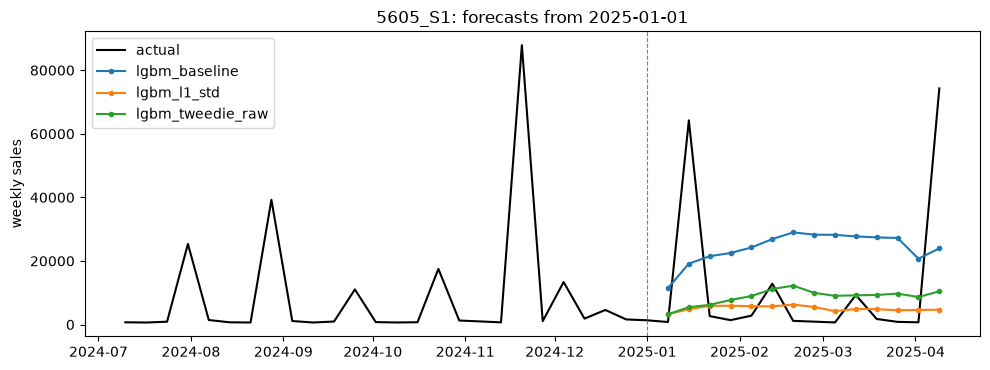

In [9]:
cutoff = DEV_CUTOFFS[-1]
recent = actuals[(actuals.ds <= cutoff) & (actuals.ds > cutoff - pd.Timedelta(weeks=26))]
level = recent.groupby("unique_id").y.agg(["mean", "median"])
peak = recent[recent.ds > cutoff - pd.Timedelta(weeks=13)].groupby("unique_id").y.max()
spikiness = (peak / level["median"]).where((level["mean"] >= level["mean"].quantile(2 / 3)) & (level["median"] > 0))
sku = spikiness.idxmax()

window = actuals[(actuals.unique_id == sku) & (actuals.ds > cutoff - pd.Timedelta(weeks=26)) & (actuals.ds <= cutoff + pd.Timedelta(weeks=H))]
shown = candidates[(candidates.unique_id == sku) & (candidates.cutoff == cutoff) & candidates.model.isin(["lgbm_baseline", "lgbm_l1_std", "lgbm_tweedie_raw"])]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(window.ds, window.y, color="black", label="actual")
for model, rows in shown.groupby("model"):
    ax.plot(rows.ds, rows.yhat, marker=".", label=model)
ax.axvline(cutoff, color="grey", ls="--", lw=0.8)
ax.set(title=f"{sku}: forecasts from {cutoff:%Y-%m-%d}", ylabel="weekly sales")
ax.legend()
plt.tight_layout()

L2 carries the past spikes into the level of every forecast week. L1 stays near an ordinary week, and Tweedie sits between them. None of the three can know when the next spike comes, because these models get no promotion information.

## 6. Zero-heavy and low-volume products

Intermittency groups products by the share of zero-sales weeks in their history: regular (up to 10%), some zeros (10 to 50%), zero heavy (over 50%). If lower WAPE comes with a large negative bias, the model is winning by forecasting too little.

In [10]:
by_zeros = breakdown(candidates, actuals, "intermittency", scope="dev", segments=segments)
pd.concat({
    "wape": by_zeros.pivot(index="model", columns="intermittency", values="wape"),
    "bias": by_zeros.pivot(index="model", columns="intermittency", values="bias"),
}, axis=1).loc[design.index].round(3)

wape                          bias             \
intermittency       regular some_zeros zero_heavy regular some_zeros   
lgbm_baseline         0.371      0.580      1.393   0.109      0.224   
lgbm_l1_std           0.319      0.489      0.842  -0.060      0.049   
lgbm_quantile60_std   0.366      0.592      0.874   0.106      0.292   
lgbm_raw              0.382      0.580      1.346  -0.002      0.129   
lgbm_l1_raw           0.361      0.500      0.756  -0.153     -0.107   
lgbm_tweedie_raw      0.376      0.544      0.809  -0.002      0.041   

                                
intermittency       zero_heavy  
lgbm_baseline           -0.099  
lgbm_l1_std             -0.711  
lgbm_quantile60_std     -0.523  
lgbm_raw                 0.465  
lgbm_l1_raw             -0.380  
lgbm_tweedie_raw        -0.139

In [11]:
by_volume = breakdown(candidates, actuals, "volume", scope="dev", segments=segments)
pd.concat({
    "wape": by_volume.pivot(index="model", columns="volume", values="wape"),
    "bias": by_volume.pivot(index="model", columns="volume", values="bias"),
}, axis=1).loc[design.index].round(3)

wape                 bias              
volume                high    low    mid   high    low    mid
lgbm_baseline        0.439  0.735  0.543  0.145 -0.026  0.087
lgbm_l1_std          0.369  0.636  0.456 -0.033 -0.230 -0.091
lgbm_quantile60_std  0.431  0.714  0.528  0.154  0.009  0.113
lgbm_raw             0.434  2.681  0.508  0.021  2.408  0.088
lgbm_l1_raw          0.403  0.649  0.447 -0.150 -0.210 -0.058
lgbm_tweedie_raw     0.425  0.799  0.486  0.004  0.196  0.046

## 7. Reading the result

- **L1 beats L2 in both blocks, at every development origin.** Standardized target: development WAPE 0.378 against 0.449 (7.3 points better on average, all seven origins), final window 0.369 against 0.419. Raw target: 0.409 against 0.456 (all seven), 0.375 against 0.505.
- **On the raw target, Tweedie sits between them.** It beats L2 by 2.4 points and loses to L1 by 2.4 points, at all seven origins each, and in the final window (0.455 against 0.375 for L1). It fixes most of the raw L2 model's low-volume problem without scaling and has the smallest development bias (+0.008), but its mean RMSSE (1.92) is worse than L1's (1.76).
- **L1's weakness is bias on zero-heavy products.** It aims at the median, so it underforecasts them (development bias -0.71 on the standardized target).
- **The 0.6 quantile** adds positive bias (+0.149) and error (0.440 against 0.378 for L1). Aiming above the median doesn't help a point forecast.
- **These differences are large.** The smallest average contrast, 2.4 points, is far above the 0.1 to 0.2 point run-to-run noise seen in notebook 03c, and each contrast holds at all seven origins, though at a few origins the gap is under half a point.

Later notebooks use **L1 on the standardized target**. In the controlled comparison it is the best objective in both blocks. Section 8 gives Tweedie a non-negative per-series scale: it gets worse, and L1 on the same scale still wins at every origin. Other variance powers are untested.

Try it later: change `tweedie_variance_power` (between 1 and 2) or the quantile `alpha`.

In [12]:
save_forecasts(forecasts, "06_objectives")

## 8. Optional: a non-negative scale for Tweedie

Tweedie was tested only on the raw target, because the z-score scaler produces negative values. Does a non-negative per-series scale help Tweedie, and does it then compete with L1 on the same scale?

- **z-score** `(y - mean) / std` centers every series at zero. Below-average weeks become negative, and zeros become a different negative number for each series.
- **max scaling** `y / max(y)` keeps zeros at zero and puts every training value in [0, 1]. The shape of a skewed, zero-heavy series is unchanged, so Tweedie can model it. A single large spike sets the scale, so ordinary weeks of a spiky series become small numbers.

MLForecast's `LocalMinMaxScaler` computes `(y - min) / (max - min)`, which is not `y / max` when a series' minimum is above zero. So a small custom transform. MLForecast calls `fit_transform` on the training rows at each origin, computes the lags and rolling means on the scaled target, and calls `inverse_transform` on the forecasts, so the scale comes only from data up to the cutoff and the forecasts return in sales units.

In [13]:
import numpy as np
from mlforecast.target_transforms import BaseTargetTransform


class LocalMaxScaler(BaseTargetTransform):
    """y / max(y) per series, from the training rows only. A series that never sold is divided by 1."""

    def fit_transform(self, df):
        self.scale_ = df.groupby(self.id_col)[self.target_col].max().where(lambda m: m > 0, 1.0)
        return df.assign(**{self.target_col: df[self.target_col] / df[self.id_col].map(self.scale_)})

    def inverse_transform(self, df):
        scale = df[self.id_col].map(self.scale_)
        models = df.columns.drop([self.id_col, self.time_col])
        return df.assign(**{m: df[m] * scale for m in models})

The two new models differ only in the objective. `lgbm_l1_std` is the benchmark; `lgbm_l1_raw` and `lgbm_tweedie_raw` above are references. The table after the loop checks the scaling at each origin: series whose history is all zeros (scale set to 1), the smallest scale, and the range of the scaled training target.

In [14]:
max_models = [
    make_model("lgbm_l1_max", {"objective": "l1"}, [LocalMaxScaler()]),
    make_model("lgbm_tweedie_max", {"objective": "tweedie", "tweedie_variance_power": 1.3}, [LocalMaxScaler()]),
]

max_forecasts, scale_checks = [], []
for cutoff in ALL_CUTOFFS:
    train = actuals[actuals.ds <= cutoff]
    for mlf in max_models:
        start = time.perf_counter()
        mlf.fit(train)
        preds = mlf.predict(H)
        name = preds.columns[-1]
        fit_seconds[name] = fit_seconds.get(name, 0) + time.perf_counter() - start
        max_forecasts.append(to_long(preds, cutoff, "06_max_scaled"))
    scale = mlf.ts.target_transforms[0].scale_
    scaled = train.y / train.unique_id.map(scale)
    scale_checks.append(dict(cutoff=cutoff.date(), series=len(scale), never_sold=int((train.groupby("unique_id").y.max() == 0).sum()),
                             smallest_scale=scale.min(), scaled_min=scaled.min(), scaled_max=scaled.max()))

max_forecasts = pd.concat(max_forecasts)
pd.DataFrame(scale_checks)

,cutoff,series,never_sold,smallest_scale,scaled_min,scaled_max
0,2024-07-17,2000,187,1.0,0.0,1.0
1,2024-08-14,2000,173,1.0,0.0,1.0
2,2024-09-11,2000,154,1.0,0.0,1.0
3,2024-10-09,2000,128,1.0,0.0,1.0
4,2024-11-06,2000,114,1.0,0.0,1.0
5,2024-12-04,2000,100,1.0,0.0,1.0
6,2025-01-01,2000,86,1.0,0.0,1.0
7,2025-02-12,2000,60,1.0,0.0,1.0
8,2025-03-12,2000,32,1.0,0.0,1.0
9,2025-04-09,2000,0,1.0,0.0,1.0


### Results

All models in sales units on identical rows.

In [15]:
max_design = pd.DataFrame({
    "scale": ["z-score", "max", "max", "raw", "raw"],
    "objective": ["L1", "L1", "Tweedie 1.3", "L1", "Tweedie 1.3"],
}, index=["lgbm_l1_std", "lgbm_l1_max", "lgbm_tweedie_max", "lgbm_l1_raw", "lgbm_tweedie_raw"])

max_candidates = pd.concat([forecasts[forecasts.model.isin(max_design.index)], max_forecasts])
max_dev = leaderboard(max_candidates, actuals, scope="dev").set_index("model")
max_final = leaderboard(max_candidates, actuals, scope="test").set_index("model")
max_table = max_design.join(max_dev[["wape", "mae", "bias", "mean_rmsse", "median_rmsse", "apc", "coverage"]])
max_table = max_table.join(max_final[["wape", "mae", "bias", "mean_rmsse"]].add_prefix("final_"))
max_table["fit_seconds"] = pd.Series(fit_seconds)
max_table.round(3)

,scale,objective,wape,mae,bias,mean_rmsse,median_rmsse,apc,coverage,final_wape,final_mae,final_bias,final_mean_rmsse,fit_seconds
lgbm_l1_std,z-score,L1,0.378,1585.149,-0.039,1.705,0.833,0.156,1.0,0.369,1500.346,-0.003,1.265,12.127
lgbm_l1_max,max,L1,0.390,1637.615,-0.042,1.728,0.837,0.181,1.0,0.379,1540.132,-0.000,1.220,13.429
lgbm_tweedie_max,max,Tweedie 1.3,0.491,2058.460,0.161,1.958,0.933,0.160,1.0,0.481,1956.433,0.197,1.311,10.675
lgbm_l1_raw,raw,L1,0.409,1714.512,-0.143,1.757,0.858,0.200,1.0,0.375,1523.835,-0.073,1.229,12.689
lgbm_tweedie_raw,raw,Tweedie 1.3,0.432,1813.335,0.008,1.918,0.951,0.216,1.0,0.455,1850.281,0.147,1.346,10.144


Paired differences in WAPE points at every origin. `better_at` counts the seven development origins where the first model wins.

In [16]:
max_by_origin = pd.concat([score(max_candidates[max_candidates.cutoff == c], actuals, rmsse=False).assign(cutoff=c.date()) for c in origins])
max_wape = max_by_origin.pivot(index="model", columns="cutoff", values="wape").loc[max_design.index]
max_contrasts = {
    "Tweedie max - L1 max": ("lgbm_tweedie_max", "lgbm_l1_max"),
    "L1 max - L1 z-score": ("lgbm_l1_max", "lgbm_l1_std"),
    "Tweedie max - L1 z-score": ("lgbm_tweedie_max", "lgbm_l1_std"),
    "Tweedie max - Tweedie raw": ("lgbm_tweedie_max", "lgbm_tweedie_raw"),
}
max_change = pd.DataFrame({name: (max_wape.loc[a] - max_wape.loc[b]) * 100 for name, (a, b) in max_contrasts.items()}).T
display(max_wape.round(3))
max_change.round(2).assign(dev_mean=max_change[dev_cols].mean(axis=1).round(2), dev_sd=max_change[dev_cols].std(axis=1).round(2),
                           better_at=(max_change[dev_cols] < 0).sum(axis=1))

cutoff,2024-07-17,2024-08-14,2024-09-11,2024-10-09,2024-11-06,2024-12-04,2025-01-01,2025-04-09
lgbm_l1_std,0.366,0.355,0.390,0.375,0.366,0.424,0.365,0.369
lgbm_l1_max,0.359,0.379,0.417,0.373,0.381,0.461,0.357,0.379
lgbm_tweedie_max,0.497,0.482,0.502,0.457,0.458,0.565,0.475,0.481
lgbm_l1_raw,0.369,0.399,0.439,0.404,0.408,0.447,0.389,0.375
lgbm_tweedie_raw,0.402,0.424,0.473,0.408,0.414,0.473,0.427,0.455


cutoff,2024-07-17,2024-08-14,2024-09-11,2024-10-09,2024-11-06,2024-12-04,2025-01-01,2025-04-09,dev_mean,dev_sd,better_at
Tweedie max - L1 max,13.75,10.36,8.48,8.38,7.67,10.35,11.83,10.23,10.12,2.16,0
L1 max - L1 z-score,-0.66,2.35,2.72,-0.27,1.50,3.74,-0.82,0.98,1.22,1.82,3
Tweedie max - L1 z-score,13.09,12.71,11.19,8.12,9.17,14.09,11.01,11.21,11.34,2.15,0
Tweedie max - Tweedie raw,9.45,5.87,2.84,4.87,4.41,9.13,4.78,2.61,5.91,2.48,0


### By demand segment

Segments from history only, recomputed at each development origin: volume and intermittency with `series_segments(panel, cutoff)`, promotion frequency as the share of promotion weeks up to the cutoff (rarely up to 5%, occasionally up to 25%, heavily above).

In [17]:
def origin_segments(cutoff):
    segments = series_segments(panel, cutoff)
    share = panel[panel.ds <= cutoff].groupby("unique_id").is_promotional.mean()
    segments["promotion"] = pd.cut(share, [-1, 0.05, 0.25, 1], labels=["rarely", "occasionally", "heavily"]).astype(str)
    return segments.assign(cutoff=cutoff).rename_axis("unique_id").reset_index()


segment_rows = max_candidates[max_candidates.cutoff.isin(DEV_CUTOFFS)].merge(pd.concat([origin_segments(c) for c in DEV_CUTOFFS]), on=["unique_id", "cutoff"])
segment_tables = {}
for segment, order in [("volume", ["low", "mid", "high"]), ("intermittency", ["regular", "some_zeros", "zero_heavy"]), ("promotion", ["rarely", "occasionally", "heavily"])]:
    scores = score(segment_rows, actuals, by=[segment], rmsse=False)
    segment_tables[(segment, "wape")] = scores.pivot(index="model", columns=segment, values="wape")[order]
    segment_tables[(segment, "bias")] = scores.pivot(index="model", columns=segment, values="bias")[order]
pd.concat(segment_tables, axis=1).loc[max_design.index].round(3)

volume                                    intermittency  \
                   wape                 bias                        wape   
                    low    mid   high    low    mid   high       regular   
lgbm_l1_std       0.775  0.441  0.367 -0.585 -0.095 -0.027         0.356   
lgbm_l1_max       0.710  0.430  0.382 -0.454 -0.029 -0.037         0.367   
lgbm_tweedie_max  0.777  0.551  0.481 -0.280  0.210  0.163         0.444   
lgbm_l1_raw       0.713  0.430  0.403 -0.470 -0.064 -0.146         0.392   
lgbm_tweedie_raw  0.779  0.464  0.425 -0.198  0.046  0.008         0.413   

                                                                      \
                                          bias                         
                 some_zeros zero_heavy regular some_zeros zero_heavy   
lgbm_l1_std           0.404      0.820  -0.021     -0.035     -0.704   
lgbm_l1_max           0.417      0.875  -0.031     -0.067     -0.098   
lgbm_tweedie_max      0.523      1.696   0.146      0.149      0.833   
lgbm_l1_raw           0.432      0.709  -0.127     -0.170     -0.382   
lgbm_tweedie_raw      0.463      0.740   0.024     -0.024     -0.140   

                 promotion                                                   
                      wape                        bias                       
                    rarely occasionally heavily rarely occasionally heavily  
lgbm_l1_std          0.262        0.440   0.394 -0.059       -0.037  -0.033  
lgbm_l1_max          0.247        0.475   0.408 -0.042        0.014  -0.062  
lgbm_tweedie_max     0.295        0.679   0.487  0.002        0.365   0.140  
lgbm_l1_raw          0.254        0.478   0.436 -0.064       -0.082  -0.193  
lgbm_tweedie_raw     0.310        0.534   0.436  0.043        0.076  -0.029

### Retrospective: weeks that turned out high

This split uses the actual target-week sales, so it describes where each model's error came from; it is not something known at the cutoff. A high week is one where sales exceeded three times the product's median weekly sales up to the cutoff. Development origins.

In [18]:
medians = pd.concat([actuals[actuals.ds <= c].groupby("unique_id").y.median().rename("median").reset_index().assign(cutoff=c) for c in DEV_CUTOFFS])
spike_rows = max_candidates[max_candidates.cutoff.isin(DEV_CUTOFFS)].merge(medians, on=["unique_id", "cutoff"]).merge(actuals, on=["unique_id", "ds"])
spike_rows["week"] = np.where(spike_rows.y > 3 * spike_rows["median"], "high", "other")
spikes = score(spike_rows.drop(columns=["y", "median"]), actuals, by=["week"], rmsse=False)
pd.concat({"wape": spikes.pivot(index="model", columns="week", values="wape"), "bias": spikes.pivot(index="model", columns="week", values="bias"),
           "rows": spikes.pivot(index="model", columns="week", values="rows")}, axis=1).loc[max_design.index].round(3)

wape          bias          rows        
week               high  other   high  other   high   other
lgbm_l1_std       0.675  0.328 -0.657  0.064  23826  172174
lgbm_l1_max       0.667  0.344 -0.607  0.053  23826  172174
lgbm_tweedie_max  0.539  0.482 -0.391  0.253  23826  172174
lgbm_l1_raw       0.697  0.361 -0.657 -0.058  23826  172174
lgbm_tweedie_raw  0.620  0.401 -0.545  0.100  23826  172174

### Reading the max-scaling result

- **Tweedie does not benefit from max scaling.** Development WAPE 0.491 against 0.432 on the raw target, worse at all seven origins (5.9 points on average), and 0.481 against 0.455 in the final window. It also overforecasts more (bias +0.161 against +0.008).
- **On the same scale L1 still wins clearly.** Max-scaled L1 beats max-scaled Tweedie by 10.1 points on average and at every origin (0.390 against 0.491; final window 0.379 against 0.481).
- **For L1 the scale matters little.** Max-scaled L1 is 1.2 points behind z-scored L1 on development (better at three of seven origins) and 1.0 behind in the final window, within the spread across origins. It does remove most of the z-score L1 bias on zero-heavy products (-0.10 against -0.70), at a slightly higher WAPE there.
- **Where Tweedie is better.** Retrospectively, in weeks that turned out above three times the product's median, max-scaled Tweedie has the lowest WAPE (0.539 against 0.675 for z-scored L1) and underforecasts least. In every other week it is much worse (0.482 against 0.328), and those weeks are 88% of the rows. Tweedie forecasts higher everywhere, which helps in spike weeks and costs more elsewhere. On the development origins raw Tweedie has the aggregate bias closest to zero (+0.008); in the final window max-scaled L1 does (-0.000).

A possible reason, not tested here: Tweedie's variance assumption depends on the units of the target, and dividing each series by its own maximum changes that relation series by series. The conclusion of section 7 stands, and later notebooks keep L1 on the z-scored target.

In [19]:
save_forecasts(max_forecasts, "06_max_scaled")